## Introdução ao Processamento de Imagem

In [1]:
!pip install opencv-python


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Dimensões: (388, 685, 3)


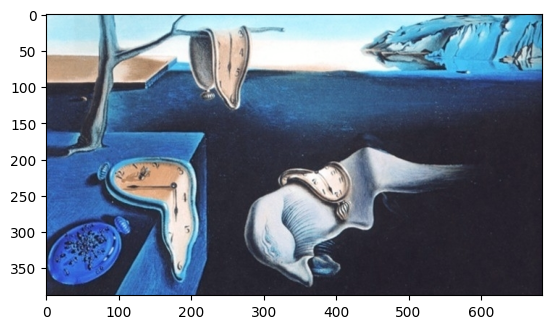

In [2]:
import cv2
import matplotlib.pyplot as plt
import urllib.request

#Baixa as imagens do repositório da disciplina
base = 'https://raw.githubusercontent.com/danilo-perico/cci620-imagens/main/'
for nome in ['dali.jpg', 'cubo.jpg']:
    urllib.request.urlretrieve(base + nome, nome)

# Lê a imagem
img = cv2.imread('dali.jpg')
# exibe com BGR
plt.imshow(img)

print(f"Dimensões: {img.shape}")

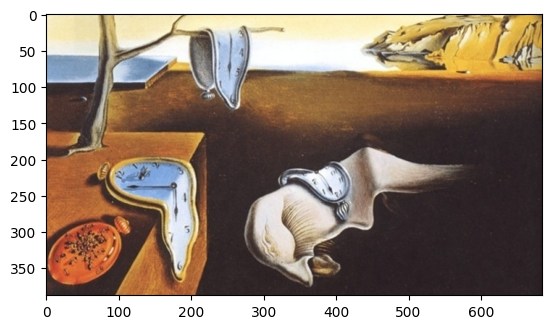

In [3]:
# Converte de BGR para RGB, já que o matplotlib espera RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Exibe a imagem
plt.imshow(img_rgb)

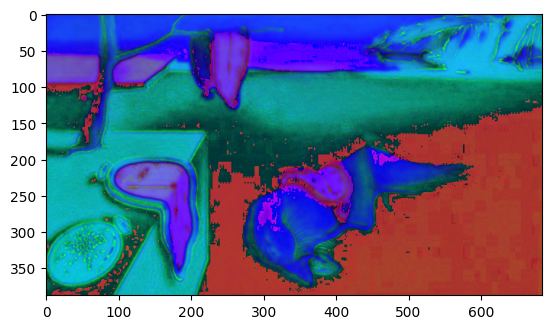

In [4]:
# Converte de BGR para HSV (Hue, Saturation, Value)
# Outro espaço de cor usado para segmentação de cor
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Exibe a imagem
plt.imshow(img_hsv)

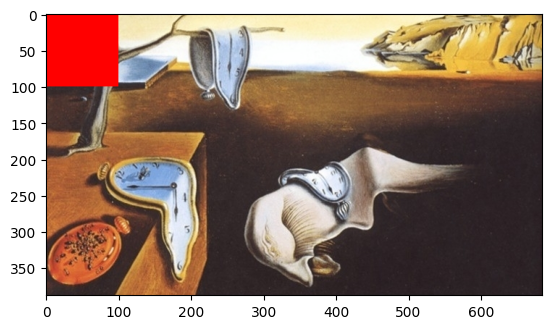

In [5]:
img_rgb_squared = img_rgb.copy()

for y in range(0, 100):
     for x in range(0, 100):
         img_rgb_squared[y, x] = (255,0,0)

# Exibe a imagem
plt.imshow(img_rgb_squared)

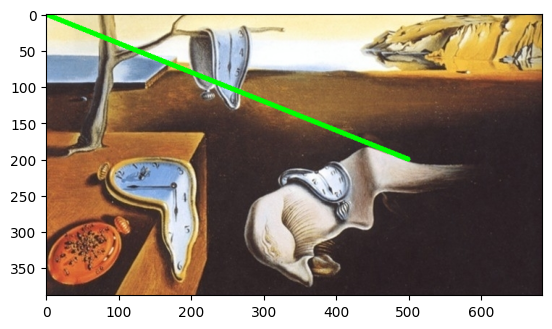

In [6]:
img_reg_line = img_rgb.copy()

verde = (0,255,0)
#imagem, posição inicial, posição final,cor, espessura da linha
cv2.line(img_reg_line, (0, 0), (500, 200), verde, 5)

# Exibe a imagem
plt.imshow(img_reg_line)

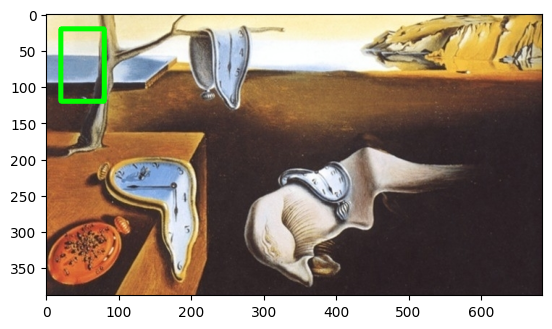

In [7]:
img_rgb_rect = img_rgb.copy()

verde = (0,255,0)
#imagem, posição inicial, posição final, cor, espessura da linha
cv2.rectangle(img_rgb_rect, (20, 20), (80, 120), verde, 5)

# Exibe a imagem
plt.imshow(img_rgb_rect)

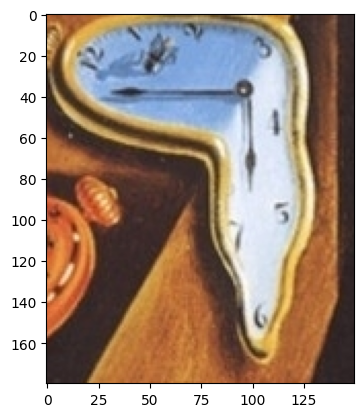

In [8]:
img_rgb_cut = img_rgb[200:380, 80:230]
plt.imshow(img_rgb_cut)

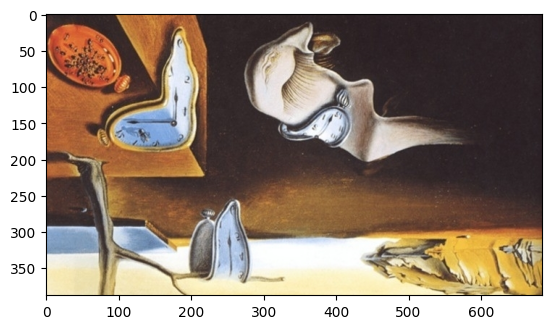

In [9]:
img_rgb_flip = img_rgb[::-1,:]
plt.imshow(img_rgb_flip)

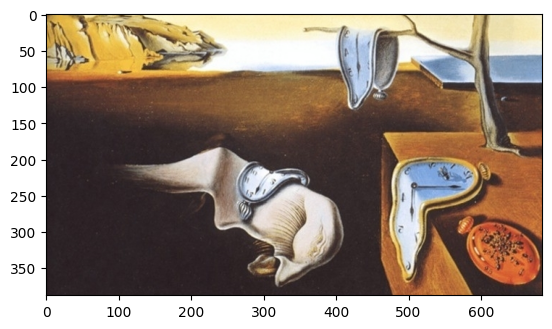

In [10]:
img_rgb_flipv = img_rgb[:,::-1]
plt.imshow(img_rgb_flipv)

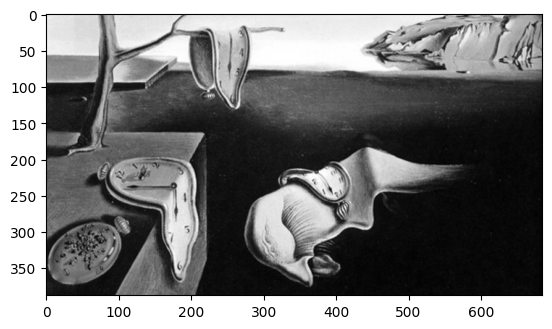

In [11]:
cinza = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
plt.imshow(cinza, cmap='gray')

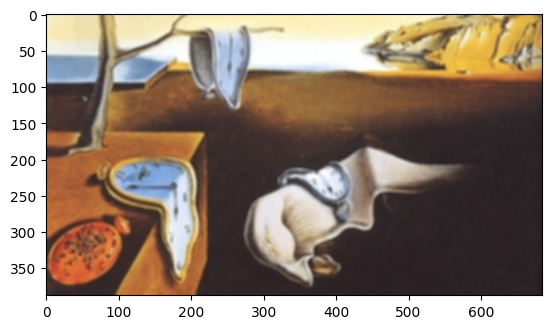

In [12]:
blur = cv2.blur(img_rgb,(5,5))
plt.imshow(blur)

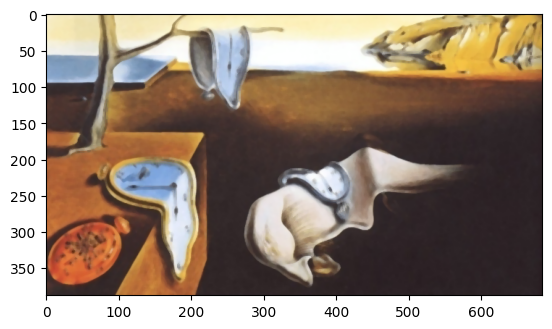

In [13]:
median = cv2.medianBlur(img_rgb,5)
plt.imshow(median)

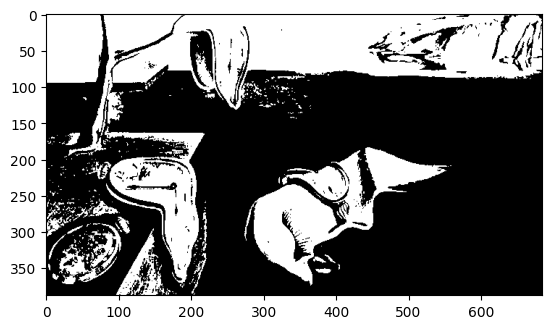

In [14]:
limiar = 127
binaria = cv2.threshold(cinza, limiar, 255, cv2.THRESH_BINARY)[1]
plt.imshow(binaria, cmap='gray')

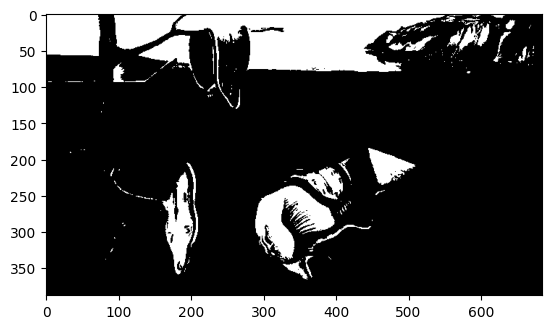

In [15]:
import cv2
import numpy as np

# cria um mínimo e um máximo diretamente em RGB: [R, G, B], cada canal de 0 a 255
lower = np.array([200, 200, 0])   # limite inferior
upper = np.array([255, 255, 255]) # limite superior

# cria a máscara direto no espaço RGB (sem conversão para HSV)
mask = cv2.inRange(img_rgb, lower, upper)

# aplica a máscara na imagem original
res = cv2.bitwise_and(img_rgb, img_rgb, mask=mask)

plt.imshow(mask, cmap="gray")

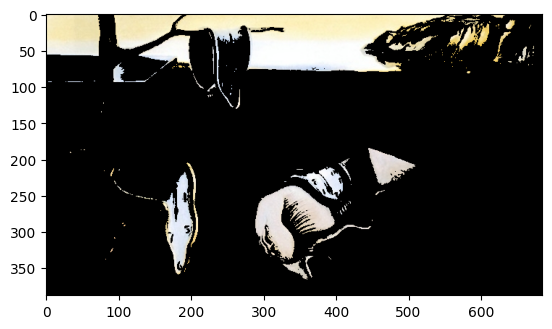

In [16]:
plt.imshow(res)

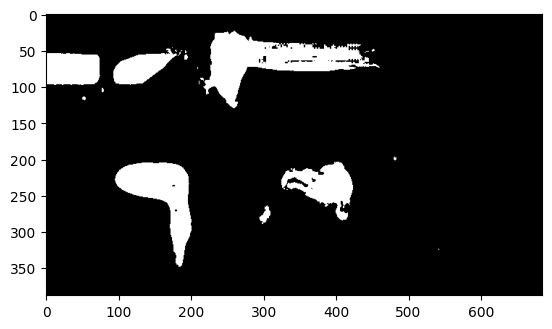

In [17]:
import cv2
import numpy as np

hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

# Matiz (Hue) de 0° a 360° (no OpenCV de 0 a 179)
# Saturação (Saturation) de 0% a 100%
# Valor (Value) de 0% a 100%

# azul fica aproximadamente entre 100 e 140 no H do OpenCV
lower = np.array([60, 0, 0])   # azul
upper = np.array([150, 255, 255])  # azul

mask = cv2.inRange(hsv, lower, upper)
res = cv2.bitwise_and(img_rgb, img_rgb, mask=mask)

plt.imshow(mask, cmap='gray')

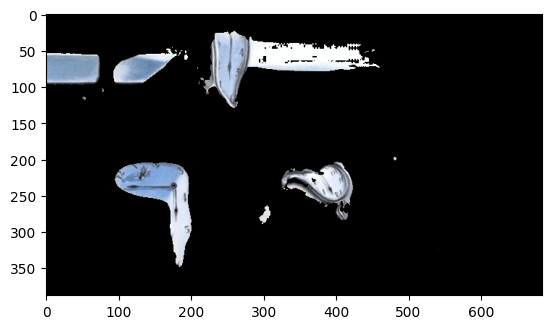

In [18]:
plt.imshow(res)

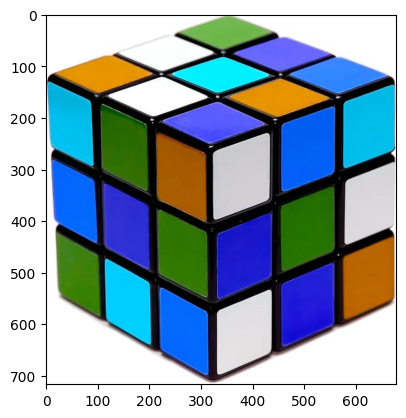

In [19]:
img_cubo = cv2.imread('cubo.jpg')
# exibe com BGR
plt.imshow(img_cubo)

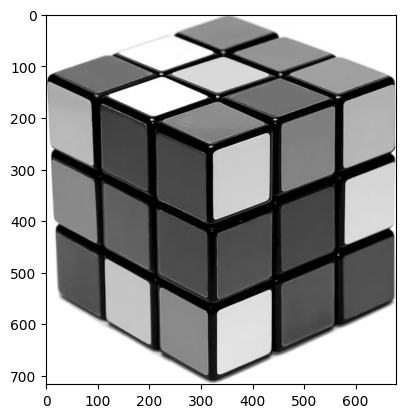

In [20]:
img_cubo_cinza = cv2.cvtColor(img_cubo, cv2.COLOR_BGR2GRAY)
plt.imshow(img_cubo_cinza, cmap="gray")

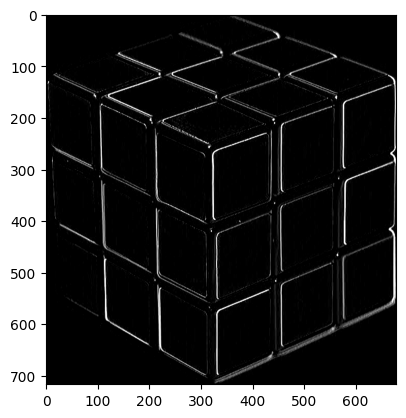

In [21]:
sobelX = cv2.Sobel(img_cubo_cinza, -1, 1, 0, 5)
sobelY = cv2.Sobel(img_cubo_cinza, -1, 0, 1, 5)

plt.imshow(sobelX, cmap="gray")

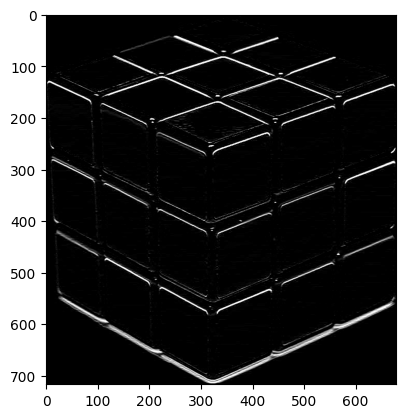

In [22]:
plt.imshow(sobelY, cmap="gray")

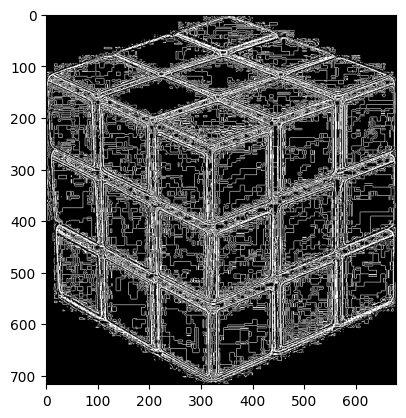

In [23]:
laplacian = cv2.Laplacian(img_cubo_cinza, cv2.CV_16S)
plt.imshow(laplacian, cmap="gray", vmin=0, vmax=1)

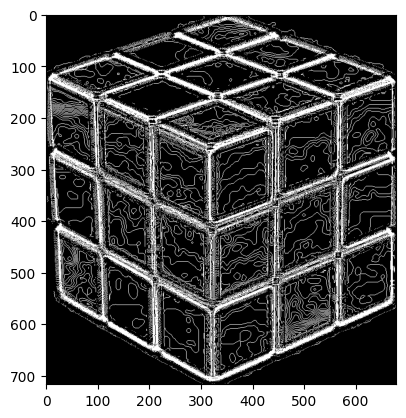

In [24]:
# Filtro para reduzir ruído
blurred = cv2.GaussianBlur(img_cubo_cinza, (11, 11), 11)
laplacian = cv2.Laplacian(blurred, cv2.CV_16S)
plt.imshow(laplacian, cmap="gray", vmin=0, vmax=1)

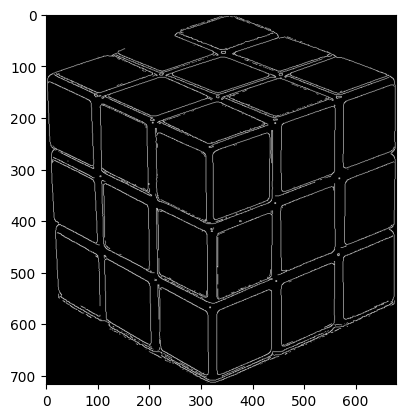

In [25]:
#imagem de entrada, threshold_baixo, threshold_alto
canny = cv2.Canny(img_cubo_cinza,100,200)
plt.imshow(canny, cmap="gray")